In [1]:

!pip -q install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("BoxOfficeIQ environment ready!")


BoxOfficeIQ environment ready!


BOXOFFICEIQ | MOVIE REVENUE INTELLIGENCE
Ramayana Case Study | Day 08

[1/12] Downloading movie datasets...
Downloaded: tmdb_5000_movies.csv
Downloaded: tmdb_5000_credits.csv

Movie dataset: (4803, 20)
Credits dataset: (4803, 4)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124



[2/12] DATA UNDERSTANDING

Column names:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-n

,0
homepage,3091
tagline,844
overview,3
runtime,2
release_date,1
id,0
budget,0
genres,0
original_title,0
popularity,0



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
budget,4803.0,2.904504e+07,4.072239e+07,0.0,790000.00000,1.500000e+07,4.000000e+07,3.800000e+08
id,4803.0,5.716548e+04,8.869461e+04,5.0,9014.50000,1.462900e+04,5.861050e+04,4.594880e+05
popularity,4803.0,2.149230e+01,3.181665e+01,0.0,4.66807,1.292159e+01,2.831350e+01,8.755813e+02
revenue,4803.0,8.226064e+07,1.628571e+08,0.0,0.00000,1.917000e+07,9.291719e+07,2.787965e+09
runtime,4801.0,1.068759e+02,2.261193e+01,0.0,94.00000,1.030000e+02,1.180000e+02,3.380000e+02
vote_average,4803.0,6.092172e+00,1.194612e+00,0.0,5.60000,6.200000e+00,6.800000e+00,1.000000e+01
vote_count,4803.0,6.902180e+02,1.234586e+03,0.0,54.00000,2.350000e+02,7.370000e+02,1.375200e+04



Duplicate records: 0

[3/12] MERGING AND CLEANING
Cleaned dataset shape: (3228, 26)

Sample cleaned data:


,title,budget,revenue,runtime,release_year
0,Avatar,237000000,2787965087,162.0,2009
1,Pirates of the Caribbean: At World's End,300000000,961000000,169.0,2007
2,Spectre,245000000,880674609,148.0,2015
3,The Dark Knight Rises,250000000,1084939099,165.0,2012
4,John Carter,260000000,284139100,132.0,2012
5,Spider-Man 3,258000000,890871626,139.0,2007
6,Tangled,260000000,591794936,100.0,2010
7,Avengers: Age of Ultron,280000000,1405403694,141.0,2015
8,Harry Potter and the Half-Blood Prince,250000000,933959197,153.0,2009
9,Batman v Superman: Dawn of Justice,250000000,873260194,151.0,2016



[4/12] EXPLORATORY DATA ANALYSIS


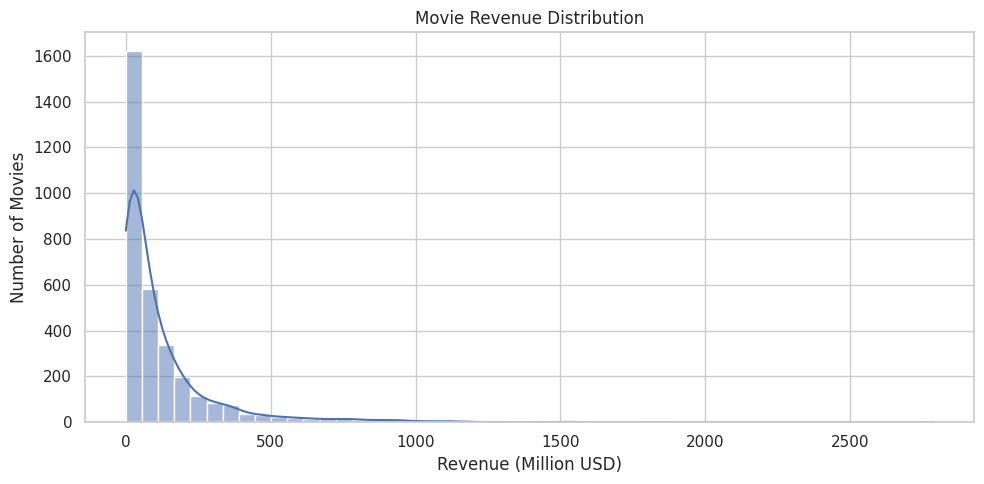

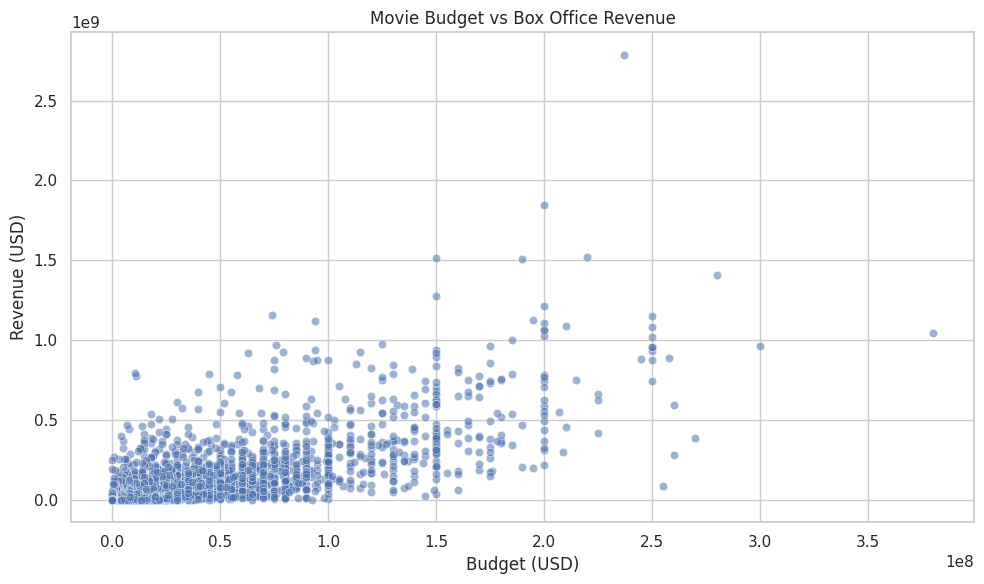

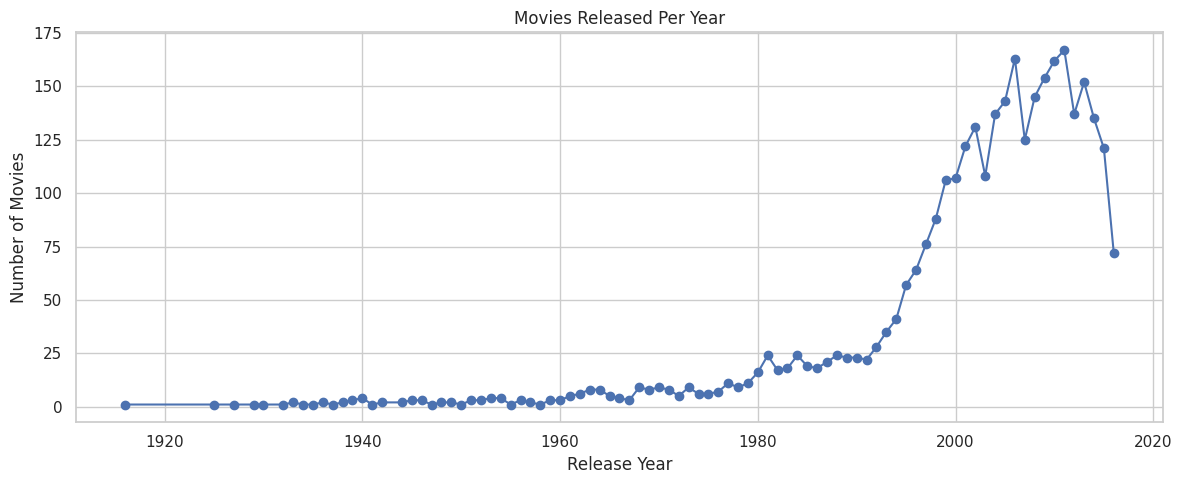

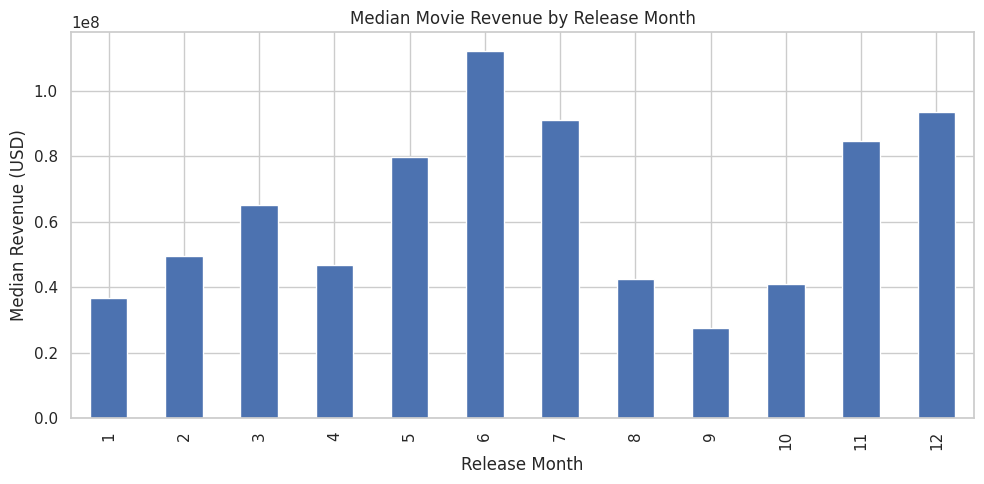

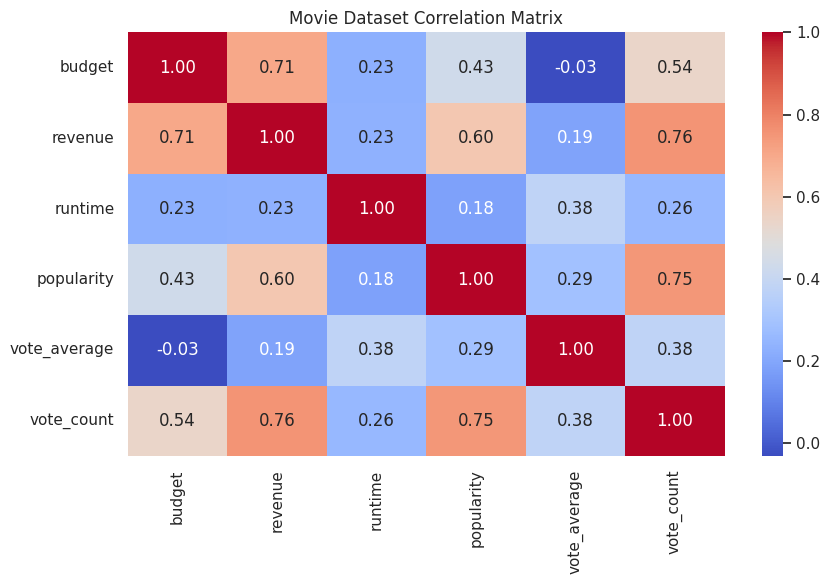


[5/12] GENRE ANALYSIS


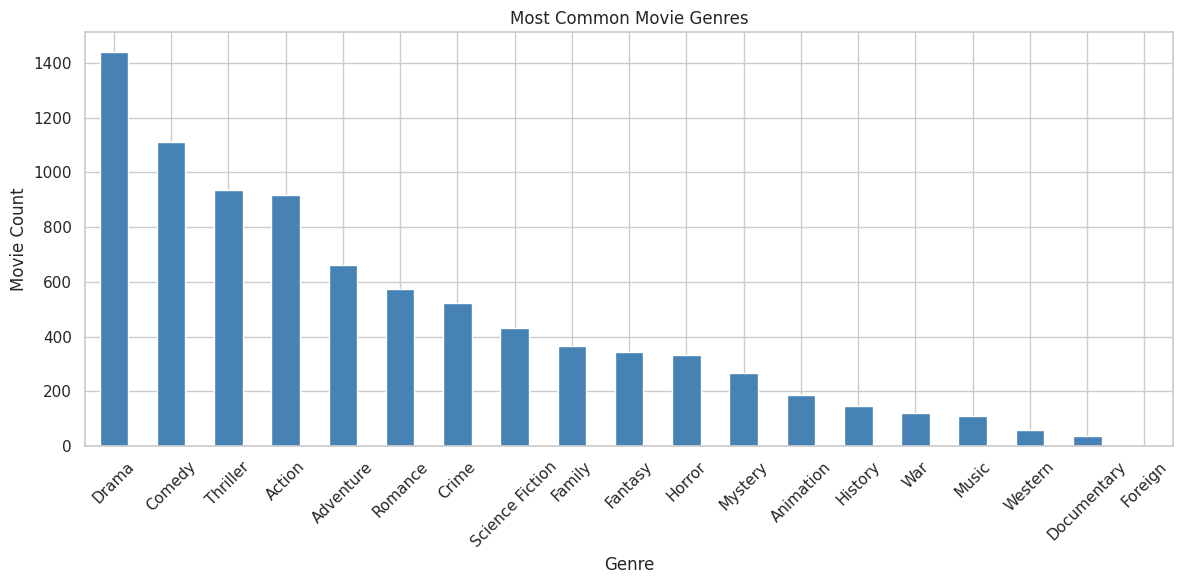

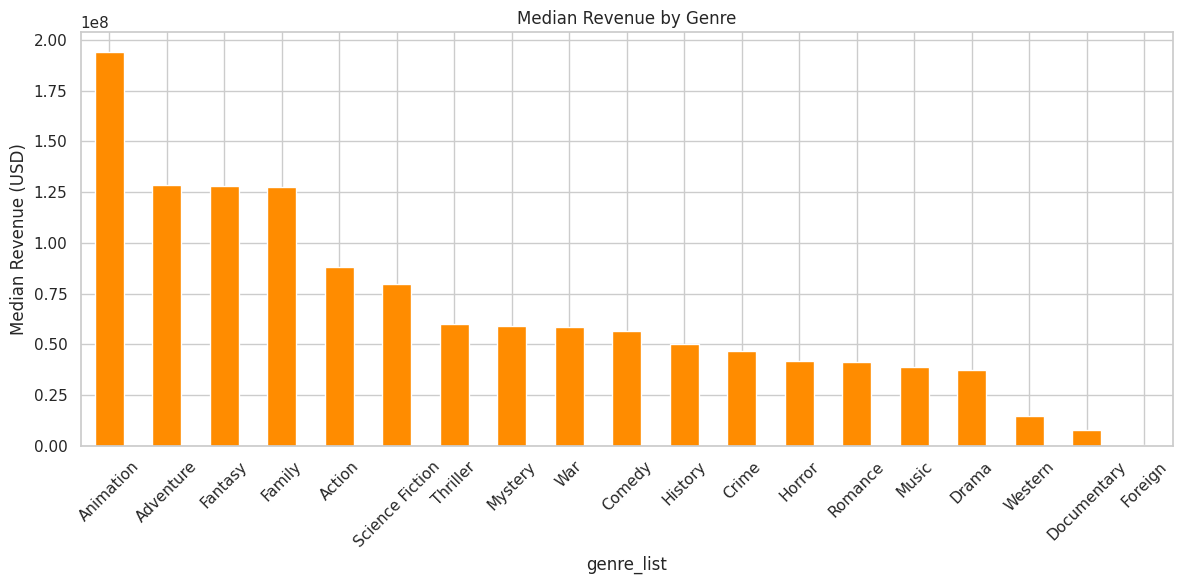


Genre counts:


,Movie Count
genre_list,
Drama,1440
Comedy,1110
Thriller,934
Action,918
Adventure,661
Romance,574
Crime,521
Science Fiction,431
Family,365



[6/12] FEATURE ENGINEERING
Feature matrix shape: (3228, 50)
Target shape: (3228,)

Features:
['budget', 'runtime', 'release_year', 'release_month', 'genre_Action', 'genre_Adventure', 'genre_Animation', 'genre_Comedy', 'genre_Crime', 'genre_Documentary', 'genre_Drama', 'genre_Family', 'genre_Fantasy', 'genre_Foreign', 'genre_History', 'genre_Horror', 'genre_Music', 'genre_Mystery', 'genre_Romance', 'genre_Science Fiction', 'genre_Thriller', 'genre_War', 'genre_Western', 'language_af', 'language_cn', 'language_da', 'language_de', 'language_en', 'language_es', 'language_fa', 'language_fr', 'language_he', 'language_hi', 'language_id', 'language_is', 'language_it', 'language_ja', 'language_ko', 'language_nb', 'language_nl', 'language_no', 'language_pl', 'language_pt', 'language_ro', 'language_ru', 'language_te', 'language_th', 'language_vi', 'language_xx', 'language_zh']

[7/12] TRAIN-TEST SPLIT
Training records: 2611
Testing records: 617
Training through year: 2011
Testing year range: 201

,Model,MAE_USD,RMSE_USD,R2
1,Random Forest,9.036306e+07,1.689206e+08,0.535582
2,Extra Trees,9.041040e+07,1.697464e+08,0.531031
0,Ridge Regression,2.720946e+08,1.097246e+09,-18.595290


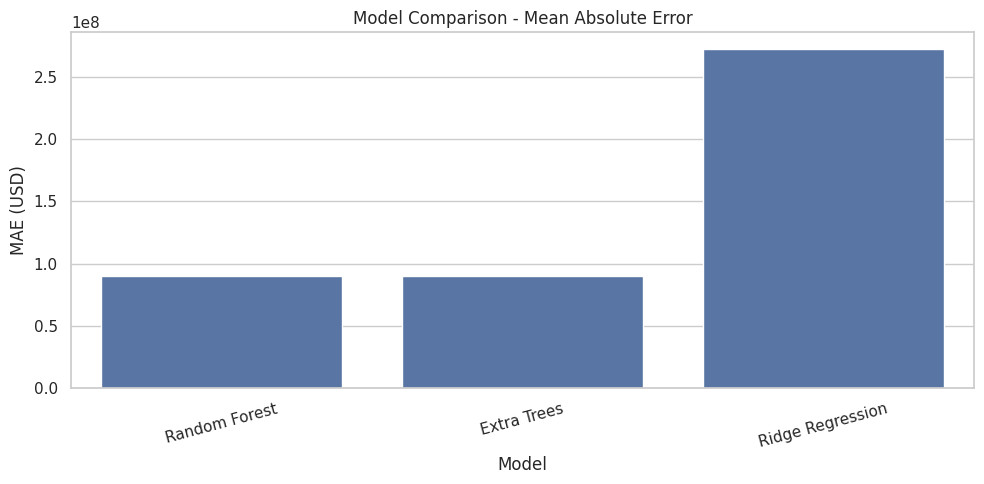

Best model by test MAE: Random Forest

[10/12] FEATURE IMPORTANCE


,Feature,Importance
0,budget,0.595026
2,release_year,0.114893
1,runtime,0.104580
3,release_month,0.063968
10,genre_Drama,0.014423
7,genre_Comedy,0.012463
18,genre_Romance,0.010708
20,genre_Thriller,0.008956
4,genre_Action,0.008379
19,genre_Science Fiction,0.008371


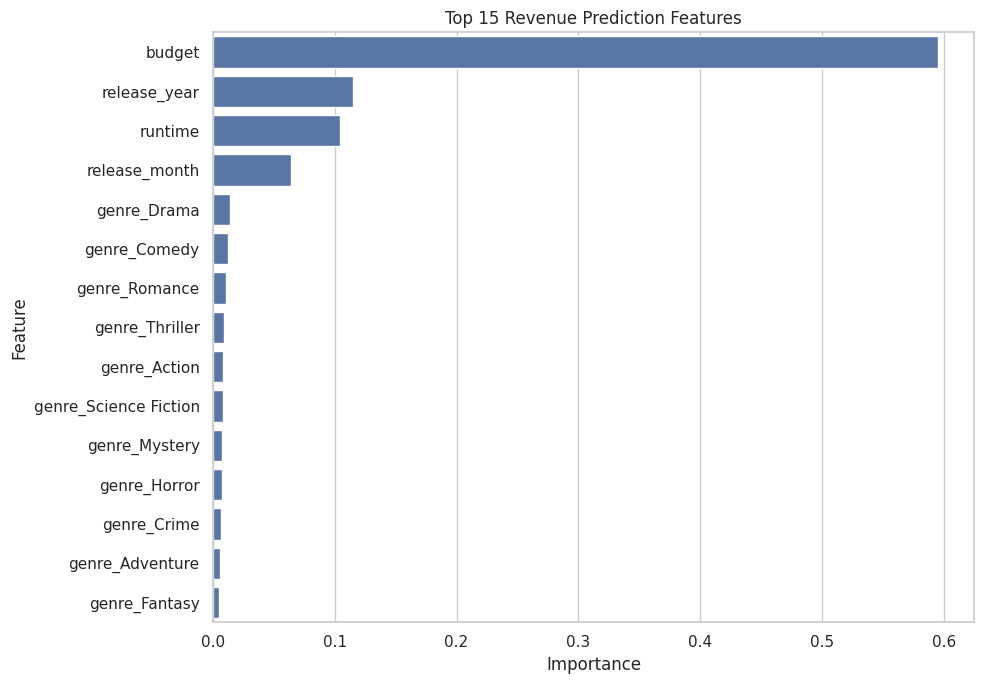


[11/12] RAMAYANA CASE STUDY

RAMAYANA | BOX OFFICE SCENARIO SIMULATOR

Enter assumptions based on a source you have verified.

Financial inputs must be entered in USD because the
historical training dataset records budget and revenue
in USD.

Leave budget or runtime blank to skip prediction.
This is an experimental model, NOT an actual forecast.

Enter assumed production budget in USD: 200
Enter assumed runtime in minutes: 190
Enter release year (press Enter for 2026): 
Enter release month (press Enter for 11): 

Scenario year 2026 is outside training period 1916-2011.
The model is extrapolating and the estimate may be unreliable.

========== RAMAYANA SCENARIO RESULT ==========
Model: Random Forest
Assumed budget: $ 200.0
Predicted revenue: $ 2280.45
Scenario revenue minus budget: $ 2080.45

Assumed genres: ['Action', 'Adventure', 'Drama', 'Fantasy']
Assumed language: Hindi

IMPORTANT:
This output is a historical-dataset-based scenario estimate.
It is not verified box-office data or a

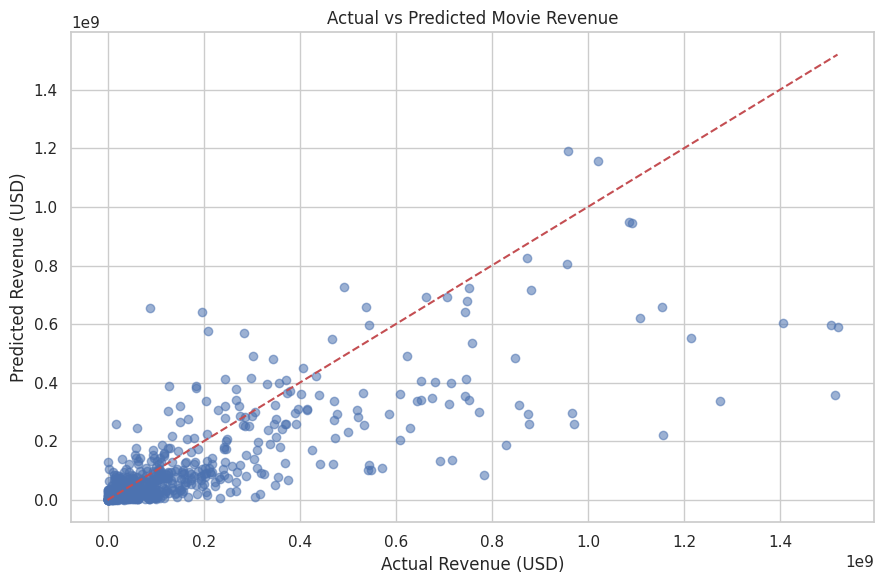


BOXOFFICEIQ PROJECT EXECUTION COMPLETED

Best model: Random Forest
Cleaned records: 3228
Visualizations and reports saved.
Output archive: BoxOfficeIQ_Day08_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:


# ================================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn requests

import os
import ast
import json
import warnings
import requests
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

os.makedirs("BoxOfficeIQ/outputs", exist_ok=True)
os.makedirs("BoxOfficeIQ/reports", exist_ok=True)

print("=" * 65)
print("BOXOFFICEIQ | MOVIE REVENUE INTELLIGENCE")
print("Ramayana Case Study | Day 08")
print("=" * 65)


# 2. AUTOMATIC DATASET DOWNLOAD
# ================================================================

print("\n[1/12] Downloading movie datasets...")

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "missvicki/TMDb-movie-data/master/"
)

files_to_download = {
    "tmdb_5000_movies.csv":
        BASE_URL + "tmdb_5000_movies.csv",

    "tmdb_5000_credits.csv":
        BASE_URL + "tmdb_5000_credits.csv"
}

for filename, url in files_to_download.items():

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    if len(response.content) < 10000:
        raise ValueError(f"Dataset download looks incomplete: {filename}")

    with open(filename, "wb") as file:
        file.write(response.content)

    print(f"Downloaded: {filename}")

movies = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv")

print("\nMovie dataset:", movies.shape)
print("Credits dataset:", credits.shape)

display(movies.head())


# 3. DATA UNDERSTANDING
# ================================================================

print("\n[2/12] DATA UNDERSTANDING")

print("\nColumn names:")
print(movies.columns.tolist())

print("\nDataset information:")
movies.info()

print("\nMissing values:")
display(movies.isnull().sum().sort_values(ascending=False))

print("\nStatistical summary:")
display(movies.describe().T)

print("\nDuplicate records:", movies.duplicated().sum())


# 4. MERGE AND DATA CLEANING
# ================================================================

print("\n[3/12] MERGING AND CLEANING")

df = movies.merge(
    credits,
    left_on="id",
    right_on="movie_id",
    how="left",
    suffixes=("", "_credits")
)

# Remove duplicate movies
df = df.drop_duplicates(subset="id")

# Convert numeric columns
numeric_columns = [
    "budget", "revenue", "runtime",
    "popularity", "vote_average", "vote_count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse release dates
df["release_date"] = pd.to_datetime(
    df["release_date"], errors="coerce"
)

df["release_year"] = df["release_date"].dt.year
df["release_month"] = df["release_date"].dt.month

# Remove records without usable financial targets
df = df[
    (df["budget"] > 0) &
    (df["revenue"] > 0) &
    (df["runtime"] > 0) &
    (df["release_year"].notna())
].copy()

# Keep released movies where status is available
df = df[df["status"].eq("Released")].copy()

# Remove impossible values
df = df[
    (df["budget"] < 1_000_000_000) &
    (df["revenue"] < 10_000_000_000) &
    (df["runtime"] < 500)
].copy()

df["release_year"] = df["release_year"].astype(int)
df["release_month"] = df["release_month"].astype(int)

print("Cleaned dataset shape:", df.shape)

print("\nSample cleaned data:")
display(
    df[[
        "title", "budget", "revenue",
        "runtime", "release_year"
    ]].head(10)
)


# 5. EXPLORATORY DATA ANALYSIS
# ================================================================

print("\n[4/12] EXPLORATORY DATA ANALYSIS")

# Revenue distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["revenue"] / 1_000_000, bins=50, kde=True)
plt.title("Movie Revenue Distribution")
plt.xlabel("Revenue (Million USD)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/revenue_distribution.png")
plt.show()

# Budget vs Revenue
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="budget",
    y="revenue",
    alpha=0.55
)
plt.title("Movie Budget vs Box Office Revenue")
plt.xlabel("Budget (USD)")
plt.ylabel("Revenue (USD)")
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/budget_vs_revenue.png")
plt.show()

# Movies released per year
yearly = df.groupby("release_year").size()

plt.figure(figsize=(12, 5))
yearly.plot(kind="line", marker="o")
plt.title("Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/yearly_releases.png")
plt.show()

# Average revenue by release month
monthly = df.groupby("release_month")["revenue"].median()

plt.figure(figsize=(10, 5))
monthly.plot(kind="bar")
plt.title("Median Movie Revenue by Release Month")
plt.xlabel("Release Month")
plt.ylabel("Median Revenue (USD)")
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/monthly_revenue.png")
plt.show()

# Correlation analysis
plt.figure(figsize=(9, 6))

corr = df[
    ["budget", "revenue", "runtime",
     "popularity", "vote_average", "vote_count"]
].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Movie Dataset Correlation Matrix")
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/correlation_heatmap.png")
plt.show()


# 6. GENRE ANALYSIS
# ================================================================

print("\n[5/12] GENRE ANALYSIS")

def extract_names(value):

    try:
        parsed = ast.literal_eval(value)

        return [
            item["name"]
            for item in parsed
            if isinstance(item, dict) and "name" in item
        ]

    except (ValueError, SyntaxError, TypeError):
        return []

df["genre_list"] = df["genres"].apply(extract_names)

genre_data = df.explode("genre_list").dropna(
    subset=["genre_list"]
)

genre_counts = genre_data["genre_list"].value_counts()

plt.figure(figsize=(12, 6))
genre_counts.plot(kind="bar", color="steelblue")
plt.title("Most Common Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Movie Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/genre_distribution.png")
plt.show()

genre_revenue = genre_data.groupby(
    "genre_list"
)["revenue"].median().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
genre_revenue.plot(kind="bar", color="darkorange")
plt.title("Median Revenue by Genre")
plt.ylabel("Median Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/genre_revenue.png")
plt.show()

print("\nGenre counts:")
display(genre_counts.to_frame("Movie Count"))


# 7. FEATURE ENGINEERING
# ================================================================

print("\n[6/12] FEATURE ENGINEERING")

# Use pre-release information only.
# Do not use popularity, vote_average or vote_count.
# These are generally post-release variables.

from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

genre_features = mlb.fit_transform(df["genre_list"])

genre_df = pd.DataFrame(
    genre_features,
    columns=["genre_" + g for g in mlb.classes_],
    index=df.index
)

features = df[[
    "budget",
    "runtime",
    "release_year",
    "release_month",
    "original_language"
]].copy()

features["original_language"] = (
    features["original_language"].fillna("unknown")
)

language_features = pd.get_dummies(
    features["original_language"],
    prefix="language",
    dtype=int
)

X = pd.concat(
    [
        features.drop(columns="original_language"),
        genre_df,
        language_features
    ],
    axis=1
)

X = X.replace([np.inf, -np.inf], np.nan)

# Target variable
y = np.log1p(df["revenue"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())


# 8. CHRONOLOGICAL TRAIN-TEST SPLIT
# ================================================================

print("\n[7/12] TRAIN-TEST SPLIT")

# Train on older films and test on newer films.
# This reduces the risk of training on future records.

split_year = df["release_year"].quantile(0.80)

train_mask = df["release_year"] <= split_year
test_mask = df["release_year"] > split_year

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

if len(X_train) < 100 or len(X_test) < 30:
    raise ValueError(
        "Insufficient records for chronological evaluation."
    )

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training through year:", int(split_year))
print(
    "Testing year range:",
    int(df.loc[test_mask, "release_year"].min()),
    "to",
    int(df.loc[test_mask, "release_year"].max())
)


# 9. MACHINE LEARNING MODELS
# ================================================================

print("\n[8/12] MODEL TRAINING")

models = {
    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=18,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=250,
        max_depth=18,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, estimator in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if name == "Ridge Regression"
         else "passthrough"),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    predictions_log = pipeline.predict(X_test)

    predictions = np.maximum(
        0, np.expm1(predictions_log)
    )

    actual = np.expm1(y_test)

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    r2 = r2_score(actual, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE_USD": mae,
        "RMSE_USD": rmse,
        "R2": r2
    })

    print(f"\n{name}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2:", round(r2, 4))


# 10. MODEL COMPARISON
# ================================================================

print("\n[9/12] MODEL COMPARISON")

results_df = pd.DataFrame(results).sort_values("MAE_USD")

display(results_df)

results_df.to_csv(
    "BoxOfficeIQ/reports/model_evaluation.csv",
    index=False
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df,
    x="Model",
    y="MAE_USD"
)
plt.title("Model Comparison - Mean Absolute Error")
plt.ylabel("MAE (USD)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("BoxOfficeIQ/outputs/model_comparison.png")
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test MAE:", best_model_name)


# 11. FEATURE IMPORTANCE
# ================================================================

print("\n[10/12] FEATURE IMPORTANCE")

if best_model_name in ["Random Forest", "Extra Trees"]:

    importances = best_model.named_steps["model"].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importances
    }).sort_values(
        "Importance", ascending=False
    )

    display(importance_df.head(15))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Revenue Prediction Features")
    plt.tight_layout()

    plt.savefig(
        "BoxOfficeIQ/outputs/feature_importance.png"
    )

    plt.show()

else:
    print("Feature importance is not available for this model.")


# 12. RAMAYANA SCENARIO SIMULATOR
# ================================================================

print("\n[11/12] RAMAYANA CASE STUDY")

print("""
==========================================================
RAMAYANA | BOX OFFICE SCENARIO SIMULATOR
==========================================================

Enter assumptions based on a source you have verified.

Financial inputs must be entered in USD because the
historical training dataset records budget and revenue
in USD.

Leave budget or runtime blank to skip prediction.
This is an experimental model, NOT an actual forecast.
""")

ramayana_budget = input(
    "Enter assumed production budget in USD: "
).strip()

ramayana_runtime = input(
    "Enter assumed runtime in minutes: "
).strip()

ramayana_year = input(
    "Enter release year (press Enter for 2026): "
).strip()

ramayana_month = input(
    "Enter release month (press Enter for 11): "
).strip()

if ramayana_budget and ramayana_runtime:

    budget_value = float(ramayana_budget)
    runtime_value = float(ramayana_runtime)

    year_value = int(ramayana_year or 2026)
    month_value = int(ramayana_month or 11)

    if (
        budget_value <= 0 or
        runtime_value <= 0 or
        not 1 <= month_value <= 12
    ):
        raise ValueError("Please enter valid scenario assumptions.")

    # Editable genre assumptions
    ramayana_genres = [
        "Action",
        "Adventure",
        "Drama",
        "Fantasy"
    ]

    scenario = pd.DataFrame(
        0,
        index=[0],
        columns=X.columns
    )

    scenario["budget"] = budget_value
    scenario["runtime"] = runtime_value
    scenario["release_year"] = year_value
    scenario["release_month"] = month_value

    # Language assumption
    if "language_hi" in scenario.columns:
        scenario["language_hi"] = 1

    for genre in ramayana_genres:

        column_name = "genre_" + genre

        if column_name in scenario.columns:
            scenario[column_name] = 1

    # Check if scenario lies outside training range
    min_year = int(df.loc[train_mask, "release_year"].min())
    max_year = int(df.loc[train_mask, "release_year"].max())

    if year_value < min_year or year_value > max_year:
        print("\nWARNING:")
        print(
            f"Scenario year {year_value} is outside "
            f"training period {min_year}-{max_year}."
        )
        print(
            "The model is extrapolating and the estimate "
            "may be unreliable."
        )

    prediction_log = best_model.predict(scenario)[0]

    predicted_revenue = max(0, np.expm1(prediction_log))

    estimated_profit = predicted_revenue - budget_value

    print("\n========== RAMAYANA SCENARIO RESULT ==========")

    print("Model:", best_model_name)
    print("Assumed budget: $", round(budget_value, 2))
    print("Predicted revenue: $", round(predicted_revenue, 2))
    print("Scenario revenue minus budget: $", round(estimated_profit, 2))

    print("\nAssumed genres:", ramayana_genres)
    print("Assumed language: Hindi")

    print("""
IMPORTANT:
This output is a historical-dataset-based scenario estimate.
It is not verified box-office data or an investment forecast.

The dataset does not adequately represent the Indian film
market, Indian theatrical distribution, worldwide rights,
or the unique scale of Ramayana.
""")

    scenario_output = pd.DataFrame([{
        "Project": "Ramayana",
        "Model": best_model_name,
        "Assumed_Budget_USD": budget_value,
        "Predicted_Revenue_USD": predicted_revenue,
        "Revenue_Minus_Budget_USD": estimated_profit,
        "Scenario_Year": year_value,
        "Scenario_Month": month_value,
        "Prediction_Type": "Experimental scenario estimate"
    }])

    scenario_output.to_csv(
        "BoxOfficeIQ/reports/ramayana_scenario.csv",
        index=False
    )

else:
    print("\nScenario skipped: budget or runtime was not supplied.")
    print("No assumptions or predictions have been fabricated.")


# 13. ACTUAL VS PREDICTED ANALYSIS
# ================================================================

print("\n[12/12] FINAL MODEL DIAGNOSTICS")

test_predictions = np.maximum(
    0,
    np.expm1(best_model.predict(X_test))
)

actual_revenue = np.expm1(y_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    actual_revenue,
    test_predictions,
    alpha=0.55
)

limit = max(
    actual_revenue.max(),
    test_predictions.max()
)

plt.plot([0, limit], [0, limit], "r--")

plt.xlabel("Actual Revenue (USD)")
plt.ylabel("Predicted Revenue (USD)")
plt.title("Actual vs Predicted Movie Revenue")

plt.tight_layout()

plt.savefig(
    "BoxOfficeIQ/outputs/actual_vs_predicted.png"
)

plt.show()


# 14. SAVE PROJECT REPORT
# ================================================================

report = f"""
# BoxOfficeIQ - Day 08

## Project
Movie Revenue Prediction and Ramayana Scenario Analysis.

## Dataset
TMDB 5000 Movie Dataset.

## Records
Original movie records: {len(movies)}
Cleaned usable records: {len(df)}
Training records: {len(X_train)}
Testing records: {len(X_test)}

## Best Model
{best_model_name}

## Model Evaluation
{results_df.to_string(index=False)}

## Methodology
- Automated data acquisition
- Data cleaning
- Exploratory data analysis
- Genre feature engineering
- Chronological train-test split
- Regression modelling
- Model comparison
- Scenario analysis

## Limitations
- Historical dataset has a limited representation of Indian cinema.
- Revenue values are historical reported USD values.
- Budget and revenue records can have quality issues.
- Scenario estimates are not actual box-office forecasts.
- The model does not account for marketing, distribution,
  theatre count, ticket pricing or audience sentiment.

## Disclaimer
This project is an educational machine learning prototype.
It is not financial or investment advice.
"""

with open(
    "BoxOfficeIQ/reports/project_report.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# Save processed dataset
df.to_csv(
    "BoxOfficeIQ/reports/cleaned_movie_data.csv",
    index=False
)

# Create project ZIP
with zipfile.ZipFile(
    "BoxOfficeIQ_Day08_Outputs.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, filenames in os.walk("BoxOfficeIQ"):

        for filename in filenames:

            path = os.path.join(root, filename)

            zip_file.write(path)

print("\n" + "=" * 65)
print("BOXOFFICEIQ PROJECT EXECUTION COMPLETED")
print("=" * 65)

print("\nBest model:", best_model_name)
print("Cleaned records:", len(df))
print("Visualizations and reports saved.")
print("Output archive: BoxOfficeIQ_Day08_Outputs.zip")

from google.colab import files
files.download("BoxOfficeIQ_Day08_Outputs.zip")


BOXOFFICEIQ INDIA
Indian Cinema Revenue Intelligence
Ramayana Case Study

[1/14] DOWNLOADING INDIAN CINEMA DATA
Downloaded Boxoffice_Fact.csv: (604, 17)
Downloaded Director_dim.csv: (384, 2)
Downloaded Genere_dim.csv: (159, 2)
Downloaded Language_dim.csv: (5, 2)

Original dataset preview:


,FilmID,Title,Release Date,DirectorID,Lead Actor/Actress,LanguageID,Industry,GenreID,Budget in Crores,First Day Collection Worldwide in Crores,Worldwide Collection in Crores,Overseas Collection in Crores,India Gross Collection in Crores,Verdict,IMDb Rating,Runtime (mins),OTT Platform
0,1,PK,19-12-2014,101,Aamir Khan,501,Bollywood,601,85.0,26.6,792.0,303.0,489.0,All Time Blockbuster,8.1,153,Netflix
1,2,Happy New Year,24-10-2014,102,Shah Rukh Khan,501,Bollywood,602,150.0,61.9,397.0,102.0,295.0,Hit,5.0,180,Netflix
2,3,Kick,25-07-2014,103,Salman Khan,501,Bollywood,603,100.0,26.4,378.0,68.0,310.0,Super Hit,6.0,146,Netflix
3,4,Bang Bang,02-10-2014,104,Hrithik Roshan,501,Bollywood,604,160.0,27.5,340.0,70.0,270.0,Super Hit,5.6,153,Disney+ Hotstar
4,5,Singham Returns,15-08-2014,105,Ajay Devgn,501,Bollywood,605,80.0,32.1,216.5,16.5,200.0,Super Hit,5.7,142,Netflix



[2/14] DATA PREPARATION
Merged dataset shape: (604, 20)


,FilmID,Title,Release Date,DirectorID,Lead Actor/Actress,LanguageID,Industry,GenreID,Budget in Crores,First Day Collection Worldwide in Crores,Worldwide Collection in Crores,Overseas Collection in Crores,India Gross Collection in Crores,Verdict,IMDb Rating,Runtime (mins),OTT Platform,Director,Genre,Language
0,1,PK,19-12-2014,101,Aamir Khan,501,Bollywood,601,85.0,26.6,792.0,303.0,489.0,All Time Blockbuster,8.1,153,Netflix,Rajkumar Hirani,"Comedy, Drama, Sci-Fi",Hindi
1,2,Happy New Year,24-10-2014,102,Shah Rukh Khan,501,Bollywood,602,150.0,61.9,397.0,102.0,295.0,Hit,5.0,180,Netflix,Farah Khan,"Action, Comedy, Crime, Drama, Music",Hindi
2,3,Kick,25-07-2014,103,Salman Khan,501,Bollywood,603,100.0,26.4,378.0,68.0,310.0,Super Hit,6.0,146,Netflix,Sajid Nadiadwala,"Action, Comedy, Crime, Thriller",Hindi
3,4,Bang Bang,02-10-2014,104,Hrithik Roshan,501,Bollywood,604,160.0,27.5,340.0,70.0,270.0,Super Hit,5.6,153,Disney+ Hotstar,Siddharth Anand,"Action, Adventure, Comedy, Musical, Romance, T...",Hindi
4,5,Singham Returns,15-08-2014,105,Ajay Devgn,501,Bollywood,605,80.0,32.1,216.5,16.5,200.0,Super Hit,5.7,142,Netflix,Rohit Shetty,"Action, Crime, Drama",Hindi



[3/14] DATA CLEANING
Cleaned dataset shape: (602, 31)

Financial summary (INR Crores):


,count,mean,std,min,25%,50%,75%,max
Budget_Cr,602.0,57.563123,67.476626,2.000,20.000000,35.000000,70.00000,550.00
India_Gross_Cr,602.0,99.275249,129.827306,13.000,32.575000,57.000000,108.15000,1417.00
Worldwide_Gross_Cr,602.0,132.106296,194.075264,20.000,40.000000,69.750000,140.00000,2122.30
Gross_to_Budget_Multiple,602.0,3.160666,3.608043,0.246,1.340714,2.199231,3.44983,46.42



Missing values:


,0
FilmID,0
Title,0
Release Date,0
DirectorID,0
Lead Actor/Actress,0
LanguageID,0
Industry,0
GenreID,0
Budget in Crores,0
First Day Collection Worldwide in Crores,0



[4/14] EXPLORATORY DATA ANALYSIS


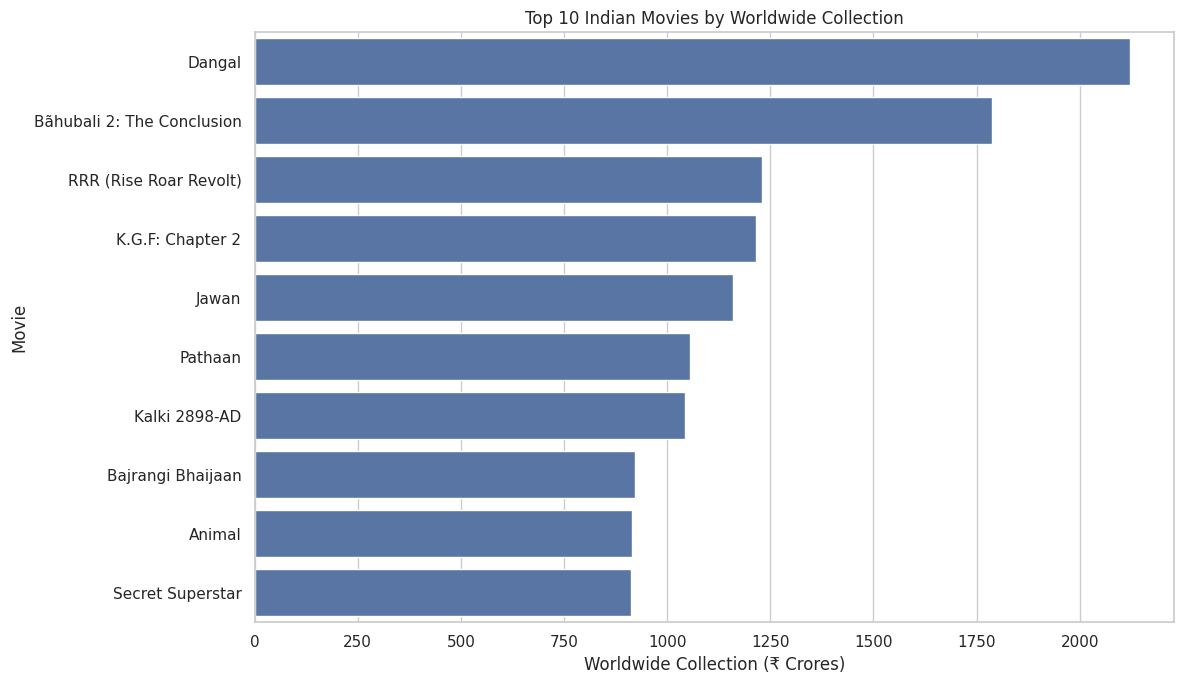

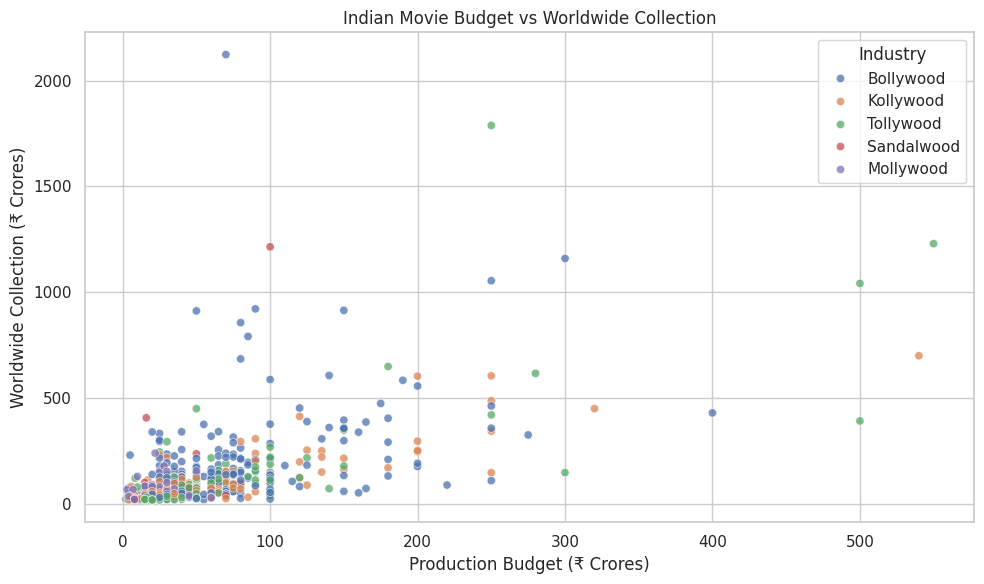

,Movie_Count,Average_Collection,Median_Collection,Average_Budget
Industry,,,,
Bollywood,180,212.555500,140.20,80.750000
Tollywood,166,108.826928,56.84,55.087349
Kollywood,140,108.828500,69.45,62.014286
Mollywood,84,54.730000,40.81,15.982143
Sandalwood,32,105.294375,49.10,29.656250


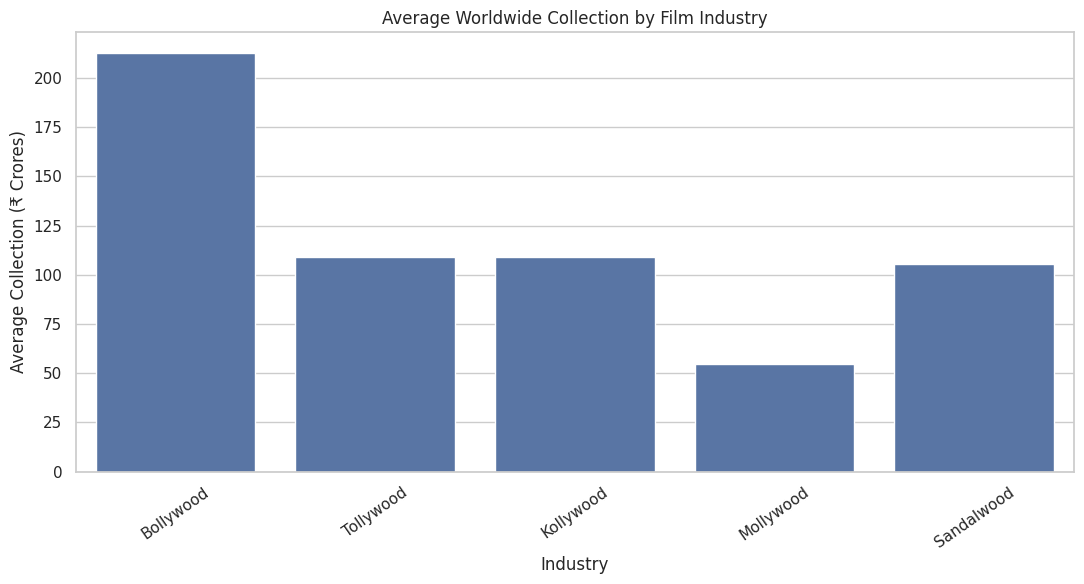

,Movies,Average_Gross
Language,,
Hindi,180,212.555500
Telugu,166,108.826928
Tamil,140,108.828500
Malayalam,84,54.730000
Kannada,32,105.294375


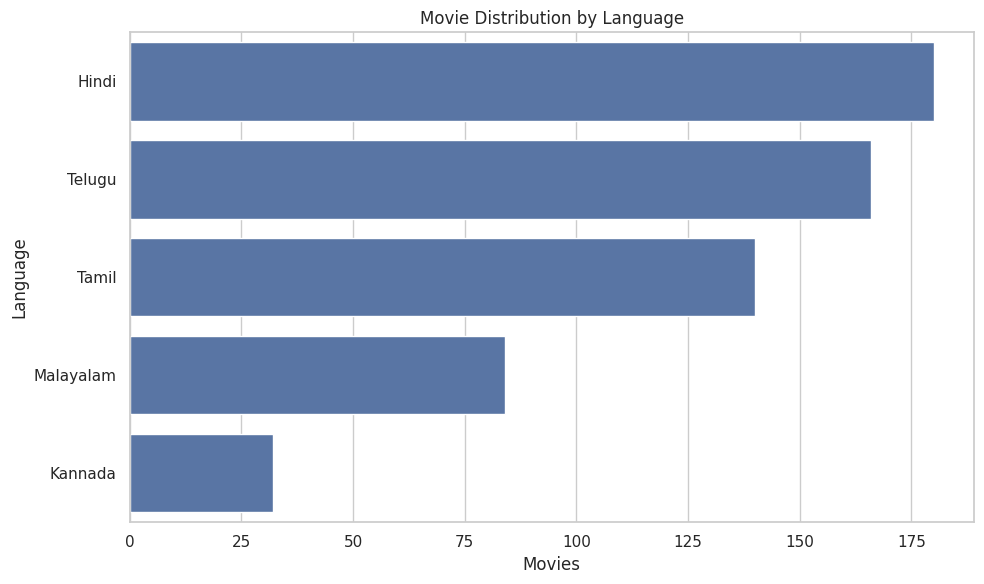

,Movies,Average_Gross
Genre,,
"Action, Biography, Drama, Sport",1,2122.300000
"Action, Adventure, Drama, Fantasy, Sci-Fi, Thriller",1,1042.250000
"Comedy, Drama, Sci-Fi",1,792.000000
"Biography, Comedy, Drama",1,588.500000
"Drama, History, Romance, War",1,585.000000
"Action, Adventure, Comedy, Drama",2,512.050000
"Drama, Music",2,507.300000
"Action, Adventure, Comedy, Drama, Romance",1,454.000000
"Action, Adventure, Thriller",7,410.245714


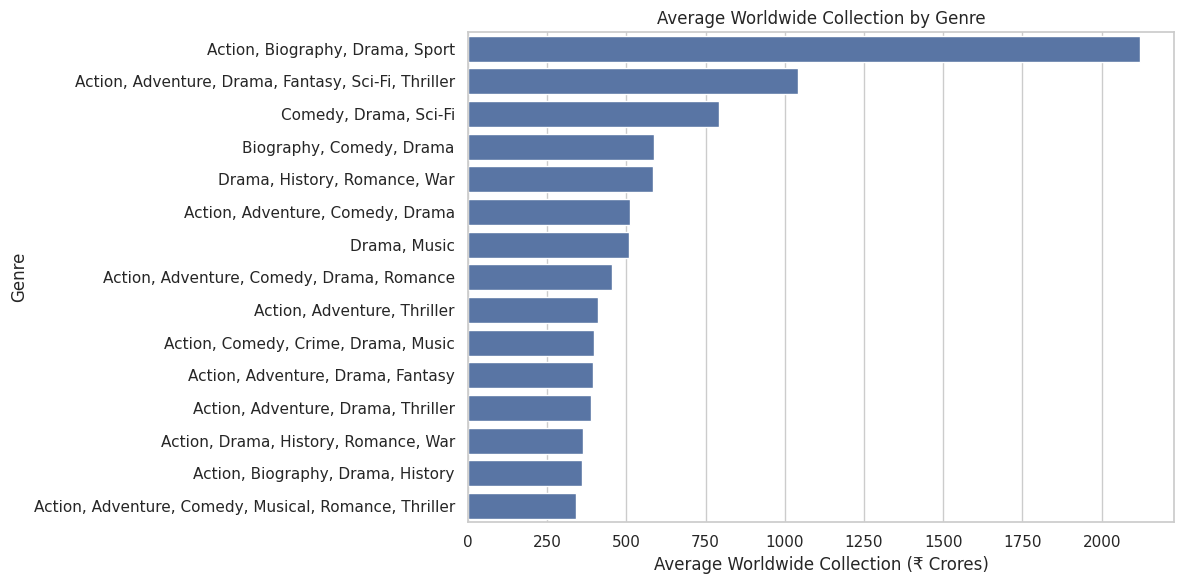

,Movies,Average_Gross,Total_Gross
Release_Year,,,
2014,32,145.156250,4645.00
2015,32,170.943750,5470.20
2016,41,172.897561,7088.80
2017,72,134.155556,9659.20
2018,71,116.553521,8275.30
2019,72,109.610000,7891.92
2020,27,86.990741,2348.75
2021,31,87.472581,2711.65
2022,80,123.164500,9853.16


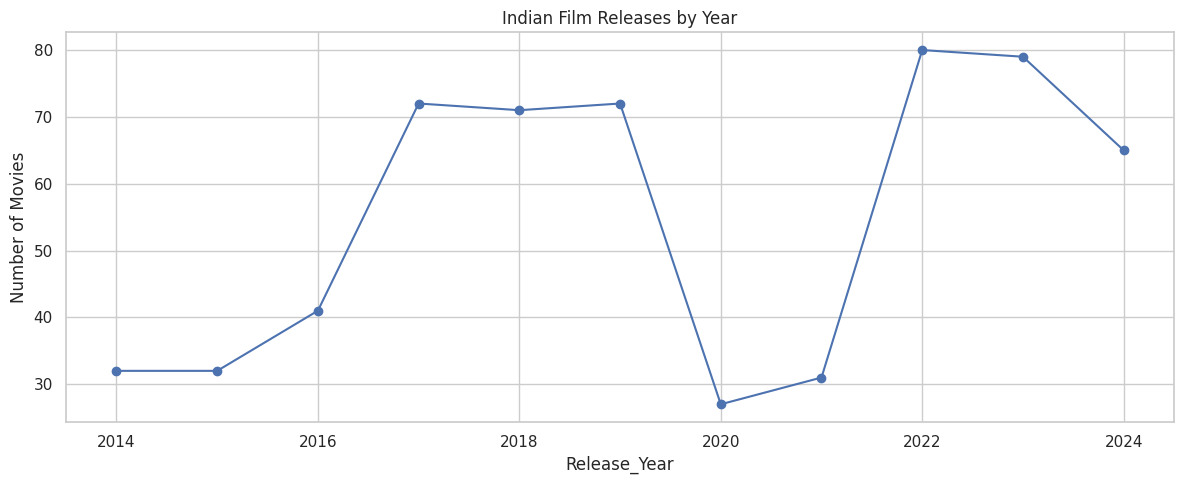

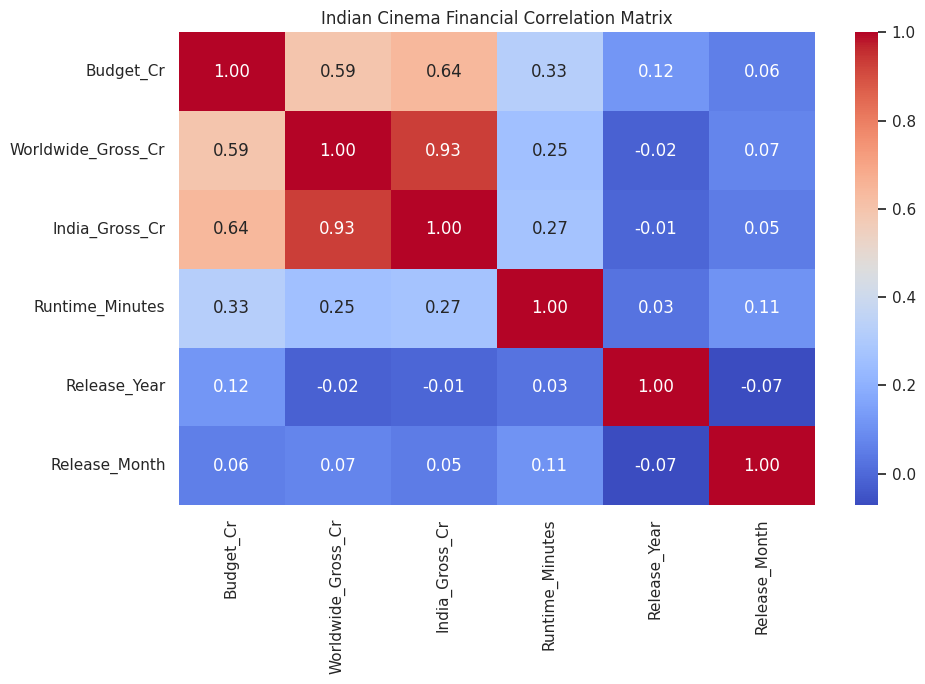


[5/14] FEATURE ENGINEERING
Feature matrix: (602, 9)
Target matrix: (602,)

Numerical features: ['Budget_Cr', 'Runtime_Minutes', 'Release_Year', 'Release_Month']
Categorical features: ['Director_Name', 'Lead_Actor', 'Language', 'Industry', 'Genre']

Target: Worldwide_Gross_Cr

[6/14] TRAIN-TEST SPLIT
Chronological evaluation selected.
Training records: 481
Testing records: 121
Training years: 2014 - 2023
Testing years: 2023 - 2024

[7/14] PREPROCESSING

[8/14] MODEL TRAINING

 Ridge Regression
MAE: 50.556 Crore
RMSE: 92.997 Crore
R2: 0.529

 Random Forest
MAE: 61.28 Crore
RMSE: 114.716 Crore
R2: 0.2834

 Extra Trees
MAE: 59.638 Crore
RMSE: 110.861 Crore
R2: 0.3307

[9/14] BASELINE COMPARISON
Median baseline MAE: 64.767

[10/14] MODEL EVALUATION


,Model,MAE_Crore,RMSE_Crore,R2_Score
0,Ridge Regression,50.556418,92.997458,0.529048
2,Extra Trees,59.637779,110.860917,0.330745
1,Random Forest,61.280261,114.716013,0.283390



Best model by test MAE: Ridge Regression


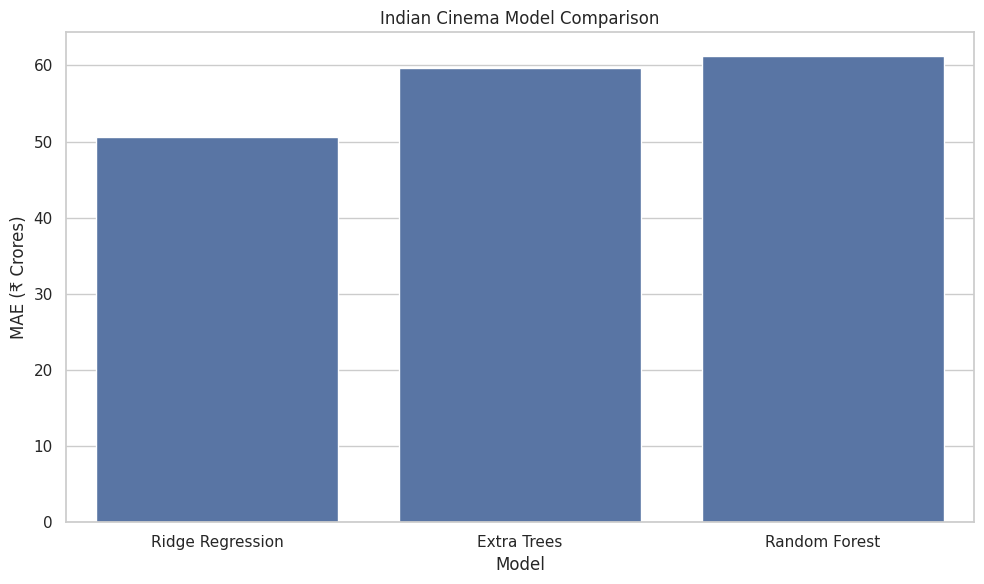

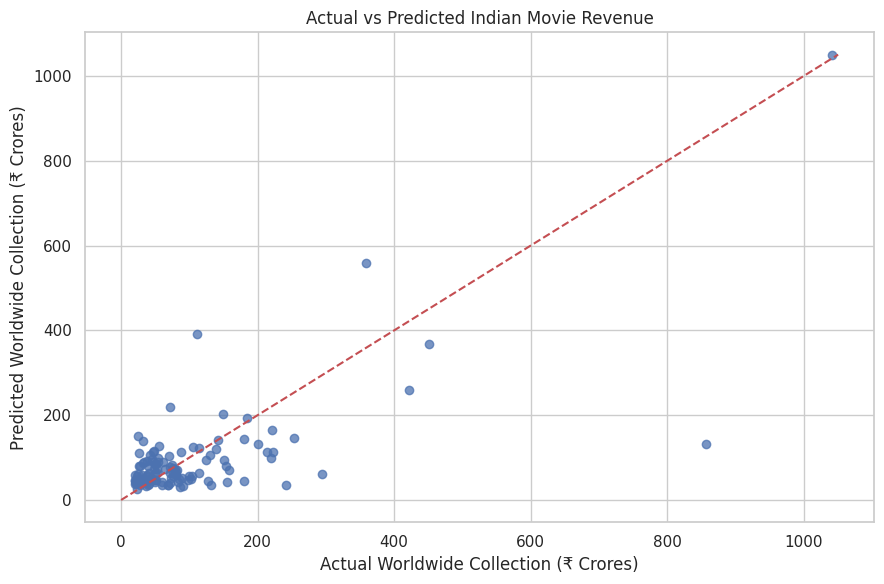


[11/14] FEATURE IMPORTANCE
Tree-based feature importance is unavailable.

[12/14] RAMAYANA SCENARIO ANALYSIS

RAMAYANA | NAMIT MALHOTRA CASE STUDY

This is a hypothetical pre-release scenario simulator.

Enter your own assumptions.
All financial inputs must be in INR CRORES.

Do not enter an unverified production budget as fact.
The simulator will not invent missing film information.


Available industries:
['Bollywood', 'Kollywood', 'Mollywood', 'Sandalwood', 'Tollywood']

Available languages:
['Hindi', 'Kannada', 'Malayalam', 'Tamil', 'Telugu']

Available genres:
['Action', 'Action, Adventure', 'Action, Adventure, Comedy', 'Action, Adventure, Comedy, Drama', 'Action, Adventure, Comedy, Drama, Fantasy', 'Action, Adventure, Comedy, Drama, Fantasy, Sci-Fi', 'Action, Adventure, Comedy, Drama, Romance', 'Action, Adventure, Comedy, Musical, Mystery', 'Action, Adventure, Comedy, Musical, Romance, Thriller', 'Action, Adventure, Crime, Drama, Thriller', 'Action, Adventure, Drama', 'Action, A

,Assumed_Budget_Cr,Estimated_Worldwide_Gross_Cr,Gross_to_Budget_Multiple
0,3200.0,5.844734e+09,1.826479e+06
1,4000.0,4.872204e+11,1.218051e+08
2,4800.0,4.061498e+13,8.461453e+09


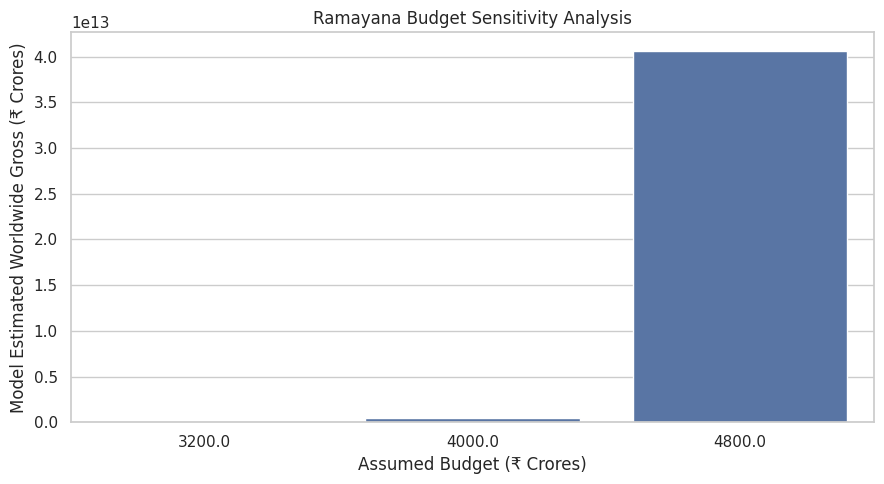


[13/14] EXPORTING PROJECT FILES

[14/14] CREATING FINAL PROJECT ARCHIVE

BOXOFFICEIQ INDIA EXECUTION COMPLETED
Cleaned Indian movie records: 602
Training records: 481
Testing records: 121
Best model: Ridge Regression

Model comparison:


,Model,MAE_Crore,RMSE_Crore,R2_Score
0,Ridge Regression,50.556418,92.997458,0.529048
2,Extra Trees,59.637779,110.860917,0.330745
1,Random Forest,61.280261,114.716013,0.283390



Project archive: BoxOfficeIQ_India_Day08.zip

Generated project files:
BoxOfficeIQ_India/requirements.txt
BoxOfficeIQ_India/README.md
BoxOfficeIQ_India/reports/ramayana_sensitivity.csv
BoxOfficeIQ_India/reports/ramayana_scenario.csv
BoxOfficeIQ_India/reports/model_evaluation.csv
BoxOfficeIQ_India/reports/source_information.json
BoxOfficeIQ_India/outputs/ramayana_sensitivity.png
BoxOfficeIQ_India/outputs/model_comparison.png
BoxOfficeIQ_India/outputs/yearly_releases.png
BoxOfficeIQ_India/outputs/industry_comparison.png
BoxOfficeIQ_India/outputs/actual_vs_predicted.png
BoxOfficeIQ_India/outputs/budget_vs_worldwide.png
BoxOfficeIQ_India/outputs/correlation_heatmap.png
BoxOfficeIQ_India/outputs/genre_performance.png
BoxOfficeIQ_India/outputs/language_distribution.png
BoxOfficeIQ_India/outputs/top_10_movies.png
BoxOfficeIQ_India/data/cleaned_indian_movies.csv
BoxOfficeIQ_India/models/boxoffice_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Your BoxOfficeIQ India project is ready for review!


In [4]:

# =====================================================================
# DAY 08: BOXOFFICEIQ INDIA
# Indian Cinema Box Office Intelligence & Revenue Prediction
# Case Study: Namit Malhotra's Ramayana
#
# Dataset: Indian Movies Box Office Collection (2014-2024)
# Target: Worldwide Collection (INR Crores)
# =====================================================================

# 1. INSTALLATION AND IMPORTS
# =====================================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn requests joblib

import os
import re
import json
import zipfile
import warnings
import requests
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

PROJECT = "BoxOfficeIQ_India"

for folder in [
    "outputs",
    "reports",
    "models",
    "data"
]:
    os.makedirs(f"{PROJECT}/{folder}", exist_ok=True)

print("=" * 75)
print("BOXOFFICEIQ INDIA")
print("Indian Cinema Revenue Intelligence")
print("Ramayana Case Study")
print("=" * 75)


# 2. AUTOMATIC DATASET ACQUISITION
# =====================================================================

print("\n[1/14] DOWNLOADING INDIAN CINEMA DATA")

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "arvindbadagi/Indian-Movies-Box-Office-Collection/main/"
)

FILES = {
    "Boxoffice_Fact.csv": "Boxoffice_Fact.csv",
    "Director_dim.csv": "Director_dim.csv",
    "Genere_dim.csv": "Genere_dim.csv",
    "Language_dim.csv": "Language_dim.csv"
}

downloaded = {}

for filename, remote_file in FILES.items():

    url = BASE_URL + remote_file

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    if len(response.content) < 20:
        raise ValueError(f"Invalid dataset file: {filename}")

    downloaded[filename] = pd.read_csv(
        BytesIO(response.content)
    )

    print(
        f"Downloaded {filename}: "
        f"{downloaded[filename].shape}"
    )

raw = downloaded["Boxoffice_Fact.csv"].copy()

print("\nOriginal dataset preview:")
display(raw.head())


# 3. DATA NORMALIZATION AND DIMENSION TABLE MERGING
# =====================================================================

print("\n[2/14] DATA PREPARATION")

def normalize_column(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def get_column(data, possible_names):

    lookup = {
        normalize_column(c): c
        for c in data.columns
    }

    for name in possible_names:

        key = normalize_column(name)

        if key in lookup:
            return lookup[key]

    return None


def merge_dimension(
    fact,
    dimension,
    fact_key_options,
    dimension_key_options,
    dimension_value_options,
    output_name
):

    left_key = get_column(fact, fact_key_options)
    right_key = get_column(dimension, dimension_key_options)
    value_key = get_column(dimension, dimension_value_options)

    if not all([left_key, right_key, value_key]):
        print(f"Could not merge {output_name}; using available ID.")
        return fact

    temp = dimension[[right_key, value_key]].drop_duplicates(
        subset=right_key
    )

    result = fact.merge(
        temp,
        left_on=left_key,
        right_on=right_key,
        how="left"
    )

    result = result.rename(
        columns={value_key: output_name}
    )

    if right_key != left_key:
        result = result.drop(columns=[right_key])

    return result


df = raw.copy()

df = merge_dimension(
    df,
    downloaded["Director_dim.csv"],
    ["DirectorID", "Director ID"],
    ["Director ID", "DirectorID"],
    ["Director"],
    "Director"
)

df = merge_dimension(
    df,
    downloaded["Genere_dim.csv"],
    ["GenreID", "Genre ID"],
    ["GenreID", "Genre ID"],
    ["Genre"],
    "Genre"
)

df = merge_dimension(
    df,
    downloaded["Language_dim.csv"],
    ["LanguageID", "Language ID"],
    ["LanguageID", "Language ID"],
    ["Language"],
    "Language"
)

print("Merged dataset shape:", df.shape)
display(df.head())


# 4. COLUMN IDENTIFICATION AND DATA CLEANING
# =====================================================================

print("\n[3/14] DATA CLEANING")

def parse_number(value):

    if pd.isna(value):
        return np.nan

    text = str(value).strip()

    if text.lower() in ["", "nan", "none", "null", "-", "na"]:
        return np.nan

    text = re.sub(r"[^0-9.\-]", "", text)

    try:
        return float(text)
    except ValueError:
        return np.nan


budget_col = get_column(
    df,
    ["Budget in Crores"]
)

worldwide_col = get_column(
    df,
    ["Worldwide Collection in Crores"]
)

india_col = get_column(
    df,
    ["India Gross Collection in Crores"]
)

date_col = get_column(
    df,
    ["Release Date"]
)

runtime_col = get_column(
    df,
    ["Runtime (mins)", "Runtime"]
)

title_col = get_column(
    df,
    ["Title"]
)

if not all([
    budget_col,
    worldwide_col,
    date_col,
    title_col
]):
    raise ValueError(
        "Required financial or date columns were not found. "
        "Inspect the source dataset schema."
    )

df["Budget_Cr"] = df[budget_col].apply(parse_number)

df["Worldwide_Gross_Cr"] = (
    df[worldwide_col].apply(parse_number)
)

if india_col:
    df["India_Gross_Cr"] = df[india_col].apply(parse_number)
else:
    df["India_Gross_Cr"] = np.nan

if runtime_col:
    df["Runtime_Minutes"] = (
        df[runtime_col].apply(parse_number)
    )
else:
    df["Runtime_Minutes"] = np.nan

df["Release_Date"] = pd.to_datetime(
    df[date_col],
    errors="coerce",
    dayfirst=True
)

df["Release_Year"] = df["Release_Date"].dt.year
df["Release_Month"] = df["Release_Date"].dt.month

df["Movie_Title"] = df[title_col].astype(str)

# Remove duplicate film IDs where available

film_id_col = get_column(df, ["FilmID"])

if film_id_col:
    df = df.drop_duplicates(subset=film_id_col)
else:
    df = df.drop_duplicates(subset=["Movie_Title", "Release_Date"])

# Keep movies with usable budget and target

df = df[
    (df["Budget_Cr"] > 0) &
    (df["Worldwide_Gross_Cr"] > 0) &
    (df["Release_Date"].notna()) &
    (df["Release_Year"] >= 1900)
].copy()

# Remove impossible financial values

df = df[
    (df["Budget_Cr"] < 10000) &
    (df["Worldwide_Gross_Cr"] < 100000)
].copy()

# Standardize categorical data

def get_text_column(data, options, fallback="Unknown"):

    col = get_column(data, options)

    if col:
        return data[col].fillna(fallback).astype(str).str.strip()

    return pd.Series(
        fallback,
        index=data.index,
        dtype="object"
    )


df["Director_Name"] = get_text_column(
    df, ["Director"]
)

df["Lead_Actor"] = get_text_column(
    df, ["Lead Actor/Actress", "Lead Actor"]
)

df["Language"] = get_text_column(
    df, ["Language"]
)

df["Industry"] = get_text_column(
    df, ["Industry"]
)

df["Genre"] = get_text_column(
    df, ["Genre"]
)

df["Industry"] = df["Industry"].replace("", "Unknown")
df["Language"] = df["Language"].replace("", "Unknown")
df["Genre"] = df["Genre"].replace("", "Unknown")

df["Gross_to_Budget_Multiple"] = (
    df["Worldwide_Gross_Cr"] / df["Budget_Cr"]
)

print("Cleaned dataset shape:", df.shape)

print("\nFinancial summary (INR Crores):")
display(
    df[
        ["Budget_Cr", "India_Gross_Cr",
         "Worldwide_Gross_Cr", "Gross_to_Budget_Multiple"]
    ].describe().T
)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))


# 5. EXPLORATORY DATA ANALYSIS
# =====================================================================

print("\n[4/14] EXPLORATORY DATA ANALYSIS")

# Top performing films

top_movies = df.nlargest(
    10,
    "Worldwide_Gross_Cr"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_movies,
    x="Worldwide_Gross_Cr",
    y="Movie_Title"
)

plt.title("Top 10 Indian Movies by Worldwide Collection")
plt.xlabel("Worldwide Collection (₹ Crores)")
plt.ylabel("Movie")

plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/top_10_movies.png"
)
plt.show()


# Budget vs worldwide collection

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Budget_Cr",
    y="Worldwide_Gross_Cr",
    hue="Industry",
    alpha=0.75
)

plt.title("Indian Movie Budget vs Worldwide Collection")
plt.xlabel("Production Budget (₹ Crores)")
plt.ylabel("Worldwide Collection (₹ Crores)")

plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/budget_vs_worldwide.png"
)
plt.show()


# Industry performance

industry_data = (
    df.groupby("Industry")
    .agg(
        Movie_Count=("Movie_Title", "count"),
        Average_Collection=("Worldwide_Gross_Cr", "mean"),
        Median_Collection=("Worldwide_Gross_Cr", "median"),
        Average_Budget=("Budget_Cr", "mean")
    )
    .sort_values("Movie_Count", ascending=False)
)

display(industry_data)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=industry_data.reset_index(),
    x="Industry",
    y="Average_Collection"
)

plt.title("Average Worldwide Collection by Film Industry")
plt.ylabel("Average Collection (₹ Crores)")
plt.xticks(rotation=35)

plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/industry_comparison.png"
)
plt.show()


# Language analysis

language_data = (
    df.groupby("Language")
    .agg(
        Movies=("Movie_Title", "count"),
        Average_Gross=("Worldwide_Gross_Cr", "mean")
    )
    .sort_values("Movies", ascending=False)
)

display(language_data)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=language_data.reset_index(),
    x="Movies",
    y="Language"
)

plt.title("Movie Distribution by Language")
plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/language_distribution.png"
)
plt.show()


# Genre analysis

genre_data = (
    df.groupby("Genre")
    .agg(
        Movies=("Movie_Title", "count"),
        Average_Gross=("Worldwide_Gross_Cr", "mean")
    )
    .sort_values("Average_Gross", ascending=False)
)

display(genre_data.head(15))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_data.head(15).reset_index(),
    x="Average_Gross",
    y="Genre"
)

plt.title("Average Worldwide Collection by Genre")
plt.xlabel("Average Worldwide Collection (₹ Crores)")

plt.tight_layout()
plt.savefig(
    f"{PROJECT}/outputs/genre_performance.png"
)
plt.show()


# Yearly trends

yearly = (
    df.groupby("Release_Year")
    .agg(
        Movies=("Movie_Title", "count"),
        Average_Gross=("Worldwide_Gross_Cr", "mean"),
        Total_Gross=("Worldwide_Gross_Cr", "sum")
    )
)

display(yearly)

plt.figure(figsize=(12, 5))

yearly["Movies"].plot(
    marker="o"
)

plt.title("Indian Film Releases by Year")
plt.ylabel("Number of Movies")
plt.tight_layout()

plt.savefig(
    f"{PROJECT}/outputs/yearly_releases.png"
)
plt.show()


# Correlation

numeric_eda = [
    "Budget_Cr",
    "Worldwide_Gross_Cr",
    "India_Gross_Cr",
    "Runtime_Minutes",
    "Release_Year",
    "Release_Month"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_eda].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Indian Cinema Financial Correlation Matrix")
plt.tight_layout()

plt.savefig(
    f"{PROJECT}/outputs/correlation_heatmap.png"
)
plt.show()


# 6. FEATURE ENGINEERING
# =====================================================================

print("\n[5/14] FEATURE ENGINEERING")

# Pre-release features only

numeric_features = [
    "Budget_Cr",
    "Runtime_Minutes",
    "Release_Year",
    "Release_Month"
]

categorical_features = [
    "Director_Name",
    "Lead_Actor",
    "Language",
    "Industry",
    "Genre"
]

feature_columns = (
    numeric_features +
    categorical_features
)

model_data = df[
    feature_columns + ["Worldwide_Gross_Cr"]
].copy()

model_data = model_data.replace(
    [np.inf, -np.inf],
    np.nan
)

# Budget and target are essential

model_data = model_data.dropna(
    subset=["Budget_Cr", "Worldwide_Gross_Cr", "Release_Year"]
)

X = model_data[feature_columns]

y = np.log1p(
    model_data["Worldwide_Gross_Cr"]
)

print("Feature matrix:", X.shape)
print("Target matrix:", y.shape)

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTarget: Worldwide_Gross_Cr")


# 7. TRAIN-TEST SPLIT
# =====================================================================

print("\n[6/14] TRAIN-TEST SPLIT")

# Chronological split: earlier films for training,
# later films for testing.

df_model = model_data.copy()

if (
    len(df_model) >= 100 and
    df_model["Release_Year"].nunique() >= 3
):

    df_model = df_model.sort_values(
        "Release_Year"
    )

    split_index = int(len(df_model) * 0.80)

    train_data = df_model.iloc[:split_index]
    test_data = df_model.iloc[split_index:]

    print("Chronological evaluation selected.")

else:

    from sklearn.model_selection import train_test_split

    train_data, test_data = train_test_split(
        df_model,
        test_size=0.20,
        random_state=RANDOM_STATE
    )

    print("Random evaluation selected due to limited data.")

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]

y_train = np.log1p(
    train_data["Worldwide_Gross_Cr"]
)

y_test = np.log1p(
    test_data["Worldwide_Gross_Cr"]
)

actual_test = test_data["Worldwide_Gross_Cr"].values

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training years:",
    train_data["Release_Year"].min(),
    "-",
    train_data["Release_Year"].max()
)

print(
    "Testing years:",
    test_data["Release_Year"].min(),
    "-",
    test_data["Release_Year"].max()
)


# 8. PREPROCESSING PIPELINE
# =====================================================================

print("\n[7/14] PREPROCESSING")

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=2,
        max_categories=40
    )

except TypeError:

    encoder = OneHotEncoder(
        handle_unknown="ignore"
    )

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="constant", fill_value="Unknown")
    ),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


# 9. MACHINE LEARNING MODEL TRAINING
# =====================================================================

print("\n[8/14] MODEL TRAINING")

models = {
    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    prediction_log = pipeline.predict(X_test)

    prediction = np.maximum(
        0,
        np.expm1(prediction_log)
    )

    mae = mean_absolute_error(
        actual_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(actual_test, prediction)
    )

    r2 = r2_score(
        actual_test,
        prediction
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE_Crore": mae,
        "RMSE_Crore": rmse,
        "R2_Score": r2
    })

    print("\n", name)
    print("MAE:", round(mae, 3), "Crore")
    print("RMSE:", round(rmse, 3), "Crore")
    print("R2:", round(r2, 4))


# 10. BASELINE COMPARISON
# =====================================================================

print("\n[9/14] BASELINE COMPARISON")

baseline_prediction = np.full(
    len(actual_test),
    train_data["Worldwide_Gross_Cr"].median()
)

baseline_mae = mean_absolute_error(
    actual_test,
    baseline_prediction
)

print("Median baseline MAE:", round(baseline_mae, 3))


# 11. MODEL EVALUATION
# =====================================================================

print("\n[10/14] MODEL EVALUATION")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "MAE_Crore"
)

display(results_df)

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("\nBest model by test MAE:", best_model_name)

results_df.to_csv(
    f"{PROJECT}/reports/model_evaluation.csv",
    index=False
)

# Model comparison chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE_Crore"
)

plt.title("Indian Cinema Model Comparison")
plt.ylabel("MAE (₹ Crores)")

plt.tight_layout()

plt.savefig(
    f"{PROJECT}/outputs/model_comparison.png"
)

plt.show()


# Actual vs predicted

best_predictions = np.maximum(
    0,
    np.expm1(best_model.predict(X_test))
)

plt.figure(figsize=(9, 6))

plt.scatter(
    actual_test,
    best_predictions,
    alpha=0.75
)

maximum = max(
    actual_test.max(),
    best_predictions.max()
)

plt.plot(
    [0, maximum],
    [0, maximum],
    "r--"
)

plt.xlabel("Actual Worldwide Collection (₹ Crores)")
plt.ylabel("Predicted Worldwide Collection (₹ Crores)")

plt.title("Actual vs Predicted Indian Movie Revenue")

plt.tight_layout()

plt.savefig(
    f"{PROJECT}/outputs/actual_vs_predicted.png"
)

plt.show()


# 12. FEATURE IMPORTANCE
# =====================================================================

print("\n[11/14] FEATURE IMPORTANCE")

if best_model_name in ["Random Forest", "Extra Trees"]:

    fitted_preprocessor = best_model.named_steps[
        "preprocessor"
    ]

    estimator = best_model.named_steps["model"]

    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

    importance = estimator.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(importance_df.head(20))

    plt.figure(figsize=(11, 8))

    sns.barplot(
        data=importance_df.head(20),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 20 Features Influencing Revenue Predictions")

    plt.tight_layout()

    plt.savefig(
        f"{PROJECT}/outputs/feature_importance.png"
    )

    plt.show()

    importance_df.to_csv(
        f"{PROJECT}/reports/feature_importance.csv",
        index=False
    )

else:

    print("Tree-based feature importance is unavailable.")


# 13. RAMAYANA SCENARIO ANALYSIS
# =====================================================================

print("\n[12/14] RAMAYANA SCENARIO ANALYSIS")

print("""
=========================================================
RAMAYANA | NAMIT MALHOTRA CASE STUDY
=========================================================

This is a hypothetical pre-release scenario simulator.

Enter your own assumptions.
All financial inputs must be in INR CRORES.

Do not enter an unverified production budget as fact.
The simulator will not invent missing film information.
""")

print("\nAvailable industries:")
print(sorted(df["Industry"].dropna().unique().tolist()))

print("\nAvailable languages:")
print(sorted(df["Language"].dropna().unique().tolist()))

print("\nAvailable genres:")
print(sorted(df["Genre"].dropna().unique().tolist()))

budget_input = input(
    "\nAssumed Ramayana production budget (₹ crore): "
).strip()

if budget_input:

    ramayana_budget = float(budget_input)

    if ramayana_budget <= 0:
        raise ValueError("Budget must be greater than zero.")

    runtime_input = input(
        "Assumed runtime in minutes (Enter to skip): "
    ).strip()

    year_input = input(
        "Release year (Enter for 2026): "
    ).strip()

    month_input = input(
        "Release month (Enter for 11): "
    ).strip()

    language_input = input(
        "Language (Enter for Hindi): "
    ).strip() or "Hindi"

    industry_input = input(
        "Industry (Enter for Bollywood): "
    ).strip() or "Bollywood"

    genre_input = input(
        "Genre (Enter for Drama): "
    ).strip() or "Drama"

    director_input = input(
        "Director (Enter for Nitesh Tiwari): "
    ).strip() or "Nitesh Tiwari"

    actor_input = input(
        "Lead actor (Enter if unspecified): "
    ).strip() or "Unknown"

    ramayana_year = int(year_input or 2026)
    ramayana_month = int(month_input or 11)

    if not 1 <= ramayana_month <= 12:
        raise ValueError("Release month must be between 1 and 12.")

    runtime_value = (
        float(runtime_input)
        if runtime_input else np.nan
    )

    # Match known categories where possible

    def match_category(value, known_values):

        lookup = {
            str(x).strip().lower(): str(x)
            for x in known_values
        }

        return lookup.get(
            str(value).strip().lower(),
            str(value).strip()
        )

    scenario = pd.DataFrame([{
        "Budget_Cr": ramayana_budget,
        "Runtime_Minutes": runtime_value,
        "Release_Year": ramayana_year,
        "Release_Month": ramayana_month,

        "Director_Name": director_input,
        "Lead_Actor": actor_input,

        "Language": match_category(
            language_input,
            df["Language"].unique()
        ),

        "Industry": match_category(
            industry_input,
            df["Industry"].unique()
        ),

        "Genre": match_category(
            genre_input,
            df["Genre"].unique()
        )
    }])

    scenario = scenario[feature_columns]

    # Extrapolation warnings

    budget_min = df["Budget_Cr"].min()
    budget_max = df["Budget_Cr"].max()

    year_min = df["Release_Year"].min()
    year_max = df["Release_Year"].max()

    print("\nSCENARIO VALIDATION")

    if ramayana_budget < budget_min or ramayana_budget > budget_max:

        print(
            "WARNING: Assumed budget is outside the "
            "historical training range."
        )

    if ramayana_year < year_min or ramayana_year > year_max:

        print(
            "WARNING: Release year is outside the "
            "historical training period."
        )

    for col in categorical_features:

        known = set(df[col].dropna().astype(str))

        if str(scenario.iloc[0][col]) not in known:

            print(
                f"WARNING: {col} '{scenario.iloc[0][col]}' "
                "was not represented in training data."
            )

    # Prediction

    ramayana_prediction = max(
        0,
        float(
            np.expm1(
                best_model.predict(scenario)[0]
            )
        )
    )

    gross_multiple = (
        ramayana_prediction / ramayana_budget
    )

    print("\n" + "=" * 55)
    print("RAMAYANA SCENARIO RESULTS")
    print("=" * 55)

    print("Selected model:", best_model_name)

    print(
        "Assumed production budget:",
        round(ramayana_budget, 2),
        "Crore"
    )

    print(
        "Scenario estimated worldwide gross:",
        round(ramayana_prediction, 2),
        "Crore"
    )

    print(
        "Estimated gross-to-budget multiple:",
        round(gross_multiple, 2),
        "x"
    )

    print("""
IMPORTANT:

This is a model-generated scenario, NOT an actual
box-office forecast.

Worldwide gross is not the same as producer profit.
The model does not know theatrical distribution,
marketing costs, rights sales, screen count or
audience demand for Ramayana.

The historical dataset is small and its coverage
may not represent the scale of this film.
""")

    # Budget sensitivity analysis

    budgets = [
        ramayana_budget * 0.80,
        ramayana_budget,
        ramayana_budget * 1.20
    ]

    sensitivity_rows = []

    for assumed_budget in budgets:

        test_scenario = scenario.copy()

        test_scenario["Budget_Cr"] = assumed_budget

        predicted = max(
            0,
            float(
                np.expm1(
                    best_model.predict(test_scenario)[0]
                )
            )
        )

        sensitivity_rows.append({
            "Assumed_Budget_Cr": assumed_budget,
            "Estimated_Worldwide_Gross_Cr": predicted,
            "Gross_to_Budget_Multiple": predicted / assumed_budget
        })

    sensitivity_df = pd.DataFrame(sensitivity_rows)

    print("\nBUDGET SENSITIVITY ANALYSIS")

    display(sensitivity_df)

    sensitivity_df.to_csv(
        f"{PROJECT}/reports/ramayana_sensitivity.csv",
        index=False
    )

    # Save scenario details

    scenario_result = pd.DataFrame([{
        "Film": "Ramayana",
        "Case_Study": "Namit Malhotra",
        "Model": best_model_name,
        "Assumed_Budget_Cr": ramayana_budget,
        "Estimated_Worldwide_Gross_Cr": ramayana_prediction,
        "Gross_to_Budget_Multiple": gross_multiple,
        "Release_Year": ramayana_year,
        "Release_Month": ramayana_month,
        "Language": language_input,
        "Industry": industry_input,
        "Genre": genre_input,
        "Prediction_Type": "Experimental scenario estimate"
    }])

    scenario_result.to_csv(
        f"{PROJECT}/reports/ramayana_scenario.csv",
        index=False
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=sensitivity_df,
        x="Assumed_Budget_Cr",
        y="Estimated_Worldwide_Gross_Cr"
    )

    plt.title("Ramayana Budget Sensitivity Analysis")
    plt.xlabel("Assumed Budget (₹ Crores)")
    plt.ylabel("Model Estimated Worldwide Gross (₹ Crores)")

    plt.tight_layout()

    plt.savefig(
        f"{PROJECT}/outputs/ramayana_sensitivity.png"
    )

    plt.show()

else:

    print(
        "Ramayana scenario skipped. "
        "No budget assumptions or predictions were created."
    )


# 14. EXPORT MODELS, REPORTS AND PROJECT FILES
# =====================================================================

print("\n[13/14] EXPORTING PROJECT FILES")

# Save trained model

joblib.dump(
    best_model,
    f"{PROJECT}/models/boxoffice_model.joblib"
)

# Save model comparison

results_df.to_csv(
    f"{PROJECT}/reports/model_evaluation.csv",
    index=False
)

# Save cleaned dataset

df.to_csv(
    f"{PROJECT}/data/cleaned_indian_movies.csv",
    index=False
)

# Save dataset source information

source_information = {
    "project": "BoxOfficeIQ India",
    "dataset": "Indian Movies Box Office Collection",
    "source": (
        "https://github.com/arvindbadagi/"
        "Indian-Movies-Box-Office-Collection"
    ),
    "period": "2014-2024 as described by the repository",
    "currency": "INR Crores",
    "target": "Worldwide Collection in Crores",
    "prediction_model": best_model_name,
    "records_used": int(len(df)),
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "disclaimer": (
        "Experimental model; not a verified forecast "
        "of any unreleased film."
    )
}

with open(
    f"{PROJECT}/reports/source_information.json",
    "w"
) as file:

    json.dump(
        source_information,
        file,
        indent=4
    )


# Generate README automatically

readme = f"""
# BoxOfficeIQ India

## Indian Cinema Revenue Intelligence

### Day 08 Data Science Portfolio Project

**Case Study:** Namit Malhotra's Ramayana

## Project Overview

BoxOfficeIQ India is a machine learning and analytics
prototype that studies Indian movie financial performance.

It explores the relationship between production budgets,
release timing, film industries, languages, genres and
worldwide box-office collections.

The project also includes an experimental Ramayana
scenario simulator.

## Dataset

Indian Movies Box Office Collection (2014-2024)

Source:
https://github.com/arvindbadagi/Indian-Movies-Box-Office-Collection

Currency: INR Crores

## Dataset Statistics

- Original records: {len(raw)}
- Cleaned records: {len(df)}
- Training records: {len(X_train)}
- Testing records: {len(X_test)}

## Machine Learning Models

- Ridge Regression
- Random Forest Regressor
- Extra Trees Regressor

## Best Model

{best_model_name}

## Model Evaluation

{results_df.to_string(index=False)}

## Features

- Data acquisition
- Data cleaning
- Exploratory data analysis
- Financial analysis
- Feature engineering
- Categorical encoding
- Regression modelling
- Chronological evaluation
- Feature importance
- Scenario analysis
- Budget sensitivity analysis

## Ramayana Case Study

The Ramayana simulator uses user-provided assumptions
to create an experimental model estimate.

It does not represent actual revenue, confirmed budget,
or a reliable commercial forecast.

## Important Limitations

- The dataset contains a limited number of movies.
- Historical box-office figures may have source limitations.
- The dataset may not cover all Indian film industries equally.
- Worldwide gross is not equivalent to producer profit.
- Future releases may fall outside the training period.
- Model estimates should not be used for investment decisions.

## Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn,
Scikit-learn and Joblib.

## Run

Open the notebook in Google Colab and execute the
complete notebook cell.

The dataset is downloaded automatically.

## Project Type

Educational machine learning prototype.
"""

with open(
    f"{PROJECT}/README.md",
    "w",
    encoding="utf-8"
) as file:

    file.write(readme)


# Requirements file

requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
requests
joblib
"""

with open(
    f"{PROJECT}/requirements.txt",
    "w"
) as file:

    file.write(requirements.strip())


# Create ZIP archive

print("\n[14/14] CREATING FINAL PROJECT ARCHIVE")

zip_name = "BoxOfficeIQ_India_Day08.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, filenames in os.walk(PROJECT):

        for filename in filenames:

            path = os.path.join(root, filename)

            archive.write(
                path,
                os.path.relpath(path, PROJECT)
            )


print("\n" + "=" * 75)
print("BOXOFFICEIQ INDIA EXECUTION COMPLETED")
print("=" * 75)

print("Cleaned Indian movie records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Best model:", best_model_name)

print("\nModel comparison:")
display(results_df)

print("\nProject archive:", zip_name)

print("\nGenerated project files:")
for root, dirs, filenames in os.walk(PROJECT):
    for filename in filenames:
        print(os.path.join(root, filename))

from google.colab import files

files.download(zip_name)

print("\nYour BoxOfficeIQ India project is ready for review!")
